In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
caminho = Path("../dados/brutos/bairros/prefeitura_bairro.gpkg")
print(Path.exists(caminho))
pref_bairro = gpd.read_file(caminho)
pref_bairro.head()

True


/home/emanu/projetos/ftl-projeto-final/.venv/lib/python3.10/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'prefeitura_bairro.gpkg': 'prefeituras_bairro_a' (default), 'layer_styles'. Specify layer parameter to avoid this warning.
  result = read_func(


,PREF_BAIRR,COD_PBR,ID,QTD_BAIRRO,area,geometry
0,Prefeitura-bairro IV - Itapuã / Ipitanga,IV,4,17,94380440.97,"MULTIPOLYGON (((563183.372 8565464.348, 563137..."
1,Prefeitura-bairro X - Valéria,X,10,4,25325166.31,"MULTIPOLYGON (((560318.999 8574966.432, 560166..."
2,Prefeitura-bairro V - Cidade Baixa,V,5,14,8132459.00,"MULTIPOLYGON (((553769.31 8569249.552, 553767...."
3,Prefeitura-bairro III - Cajazeiras,III,3,17,22160586.15,"MULTIPOLYGON (((566822.94 8573201.26, 566811.8..."
4,Prefeitura-bairro IX - Pau da Lima,IX,9,13,19905726.69,"MULTIPOLYGON (((563789.494 8569538.91, 563559...."


In [3]:
piloto = pref_bairro.loc[
    pref_bairro["COD_PBR"] == "I"
]
print("Registro(s): ",len(piloto))
print("CRS: ",piloto.crs)

Registro(s):  1
CRS:  EPSG:31984


In [4]:
piloto_wgs84 = piloto.to_crs(epsg=4326)
print("CRS original: ",piloto.crs)
print("CRS transformado: ",piloto_wgs84.crs)
print("",piloto_wgs84.total_bounds)


CRS original:  EPSG:31984
CRS transformado:  EPSG:4326
 [-38.52482824 -13.00692082 -38.46615735 -12.94804281]


In [8]:
import h3

print("Versão do H3: ",h3.__version__)

Versão do H3:  4.5.0


In [28]:
geometria_piloto = piloto_wgs84.geometry.iloc[0]
resolucao = 10

celulas = h3.geo_to_cells(
    geometria_piloto,
    res=resolucao
)

print("Resolução: ",resolucao)
print("Quantidade de células: ",len(celulas))
print("Exemplo de identificador:", next(iter(celulas)))

Resolução:  10
Quantidade de células:  1028
Exemplo de identificador: 8a8116a2418ffff


In [29]:
from shapely.geometry import Polygon

identificadores = sorted(celulas)
poligonos =  []

for identificador in identificadores:
    contorno = h3.cell_to_boundary(identificador)

    coordenadas = [
        (longitude, latitude)
        for latitude, longitude in contorno
    ]
    poligonos.append(Polygon(coordenadas))

In [30]:
grade_h3 = gpd.GeoDataFrame(
    {"h3_id": identificadores},
    geometry=poligonos,
    crs="EPSG:4326"
)

print("Dimensões:", grade_h3.shape)
grade_h3.head()

Dimensões: (1028, 2)


,h3_id,geometry
0,8a8116a24007fff,"POLYGON ((-38.50344 -12.95442, -38.50286 -12.9..."
1,8a8116a2400ffff,"POLYGON ((-38.50429 -12.95346, -38.5037 -12.95..."
2,8a8116a24017fff,"POLYGON ((-38.50214 -12.95419, -38.50156 -12.9..."
3,8a8116a2401ffff,"POLYGON ((-38.50299 -12.95323, -38.50241 -12.9..."
4,8a8116a24027fff,"POLYGON ((-38.50389 -12.95562, -38.50331 -12.9..."


In [31]:
grade_h3_utm = grade_h3.to_crs(epsg=31984)

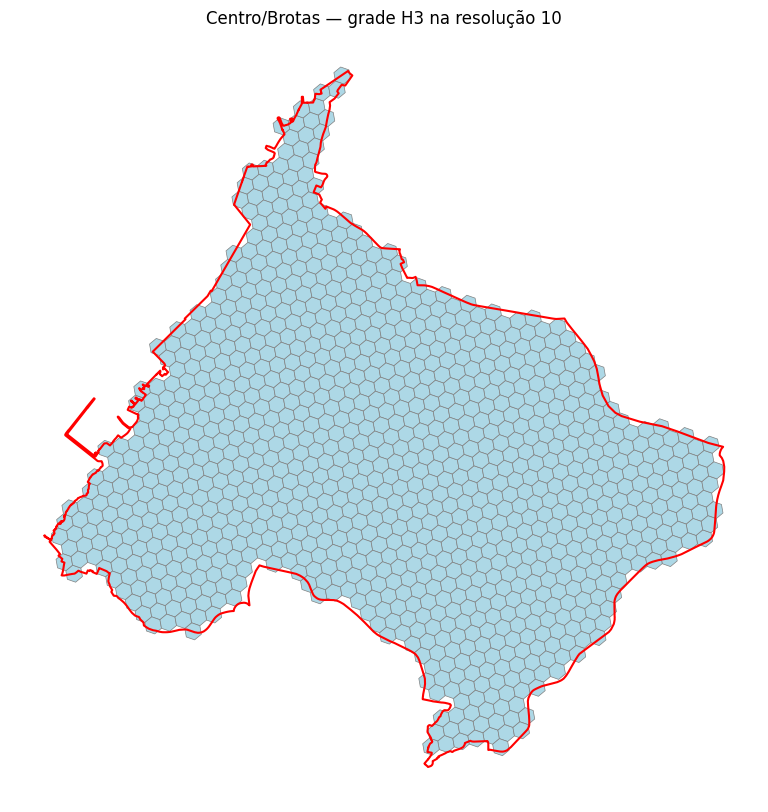

In [34]:
fig, ax = plt.subplots(figsize=(10, 10))

grade_h3_utm.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="gray",
    linewidth=0.5
)

piloto.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5
)

ax.set_title(f"Centro/Brotas — grade H3 na resolução {resolucao}")
ax.set_axis_off()

plt.show()

In [33]:
area_coberta = (
    grade_h3_utm.geometry
    .intersection(piloto.geometry.iloc[0])
    .area.sum()
)

area_piloto = piloto.geometry.area.iloc[0]

print(f"Cobertura do território: {100 * area_coberta / area_piloto:.2f}%")

Cobertura do território: 97.82%


In [35]:
print("Resolução:", resolucao)
print("Quantidade de células:", len(grade_h3))

Resolução: 10
Quantidade de células: 1028


Grade H3 na resolução 10, selecionada pelo centro das células. Cobertura de 97,82% da área de Centro/Brotas, com 2,18% sem cobertura junto às bordas.

In [36]:
forma_h3 = h3.geo_to_h3shape(geometria_piloto)

celulas_intersecao = h3.h3shape_to_cells_experimental(
    forma_h3,
    res=10,
    contain="overlap"
)

print("Células pelo centro:", len(celulas))
print("Células por interseção:", len(celulas_intersecao))

Células pelo centro: 1028
Células por interseção: 1145


In [37]:
ids_intersecao = sorted(celulas_intersecao)
poligonos_intersecao = []

for identificador in ids_intersecao:
    contorno = h3.cell_to_boundary(identificador)

    coordenadas = [
        (longitude, latitude)
        for latitude, longitude in contorno
    ]

    poligonos_intersecao.append(Polygon(coordenadas))

grade_intersecao = gpd.GeoDataFrame(
    {"h3_id": ids_intersecao},
    geometry=poligonos_intersecao,
    crs="EPSG:4326"
)

grade_intersecao_utm = grade_intersecao.to_crs(epsg=31984)

In [38]:
area_coberta_intersecao = (
    grade_intersecao_utm.geometry
    .intersection(piloto.geometry.iloc[0])
    .area.sum()
)

print(
    f"Cobertura por interseção: "
    f"{100 * area_coberta_intersecao / area_piloto:.6f}%"
)

Cobertura por interseção: 100.000000%


In [39]:
grade_recortada = grade_intersecao_utm.copy()

grade_recortada["geometry"] = (
    grade_recortada.geometry
    .intersection(piloto.geometry.iloc[0])
)

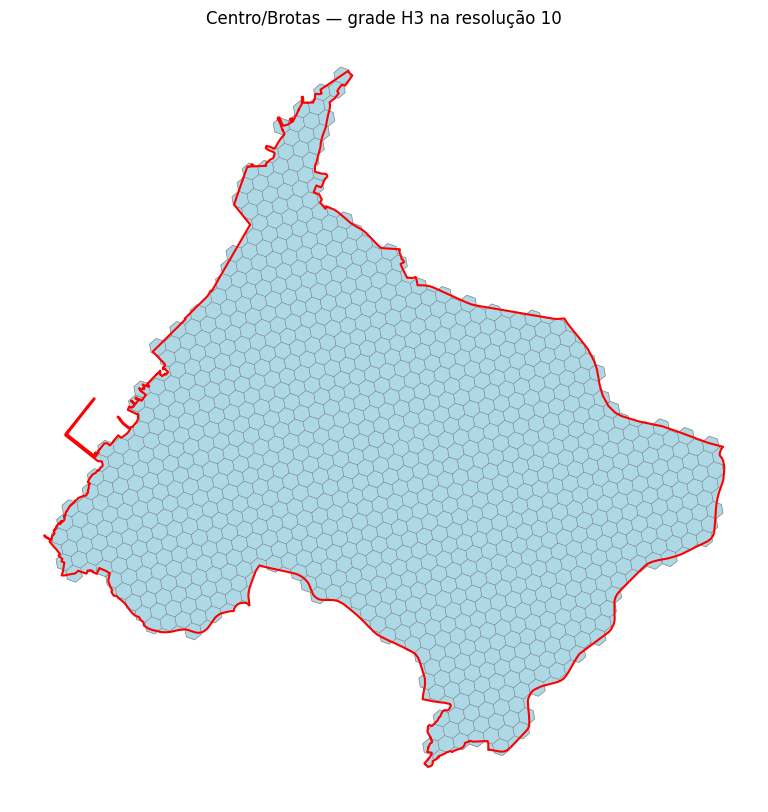

In [40]:
fig, ax = plt.subplots(figsize=(10, 10))

grade_h3_utm.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="gray",
    linewidth=0.5
)

piloto.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.5
)

grade_recortada.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="gray",
    linewidth=0.3
)

ax.set_title(f"Centro/Brotas — grade H3 na resolução {resolucao}")
ax.set_axis_off()

plt.show()

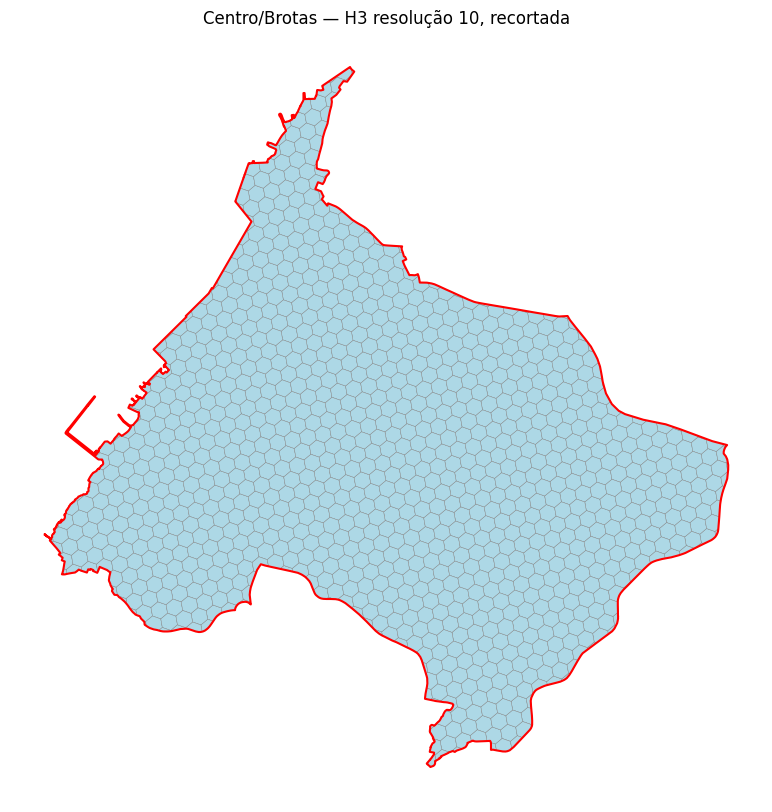

In [41]:
fig, ax = plt.subplots(figsize=(10, 10))

grade_recortada.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="gray",
    linewidth=0.3
)

piloto.boundary.plot(ax=ax, color="red", linewidth=1.5)

ax.set_title("Centro/Brotas — H3 resolução 10, recortada")
ax.set_axis_off()

plt.show()

In [42]:
print("Registros:", len(grade_recortada))
print("IDs duplicados:", grade_recortada["h3_id"].duplicated().sum())
print("Geometrias vazias:", grade_recortada.geometry.is_empty.sum())
print("Geometrias inválidas:", (~grade_recortada.geometry.is_valid).sum())
print("Tipos:")
print(grade_recortada.geometry.geom_type.value_counts())

Registros: 1145
IDs duplicados: 0
Geometrias vazias: 0
Geometrias inválidas: 0
Tipos:
Polygon         1144
MultiPolygon       1
Name: count, dtype: int64


Grade de teste na resolução H3 10, gerada com H3 4.5.0 pelo modo experimental overlap e recortada pelo limite de Centro/Brotas. Foram obtidos 1.145 registros: 1.144 Polygon e 1 MultiPolygon, sem IDs duplicados ou geometrias vazias ou inválidas. A cobertura territorial calculada foi de 100% na precisão exibida. A resolução permanece provisória.

In [43]:
pasta_saida = Path("../dados/processados")
pasta_saida.mkdir(parents=True, exist_ok=True)

arquivo_saida = pasta_saida / "centro_brotas_h3_res10.gpkg"

grade_recortada.to_file(
    arquivo_saida,
    layer="grade_recortada",
    driver="GPKG",
    index=False
)

In [44]:
grade_salva = gpd.read_file(
    arquivo_saida,
    layer="grade_recortada"
)

print("Registros:", len(grade_salva))
print("CRS:", grade_salva.crs)

Registros: 1145
CRS: EPSG:31984
